# 01 Smoke Test: Synthetic Segmentation Pipeline

This notebook verifies the refactored modular pipeline (`src/vision/segmentation`) with a fast 1-epoch smoke test,
including the evaluation metrics used in `experiments/001_pilot_synthetic`:
pixel accuracy, mean class accuracy, mIoU, foreground mIoU (background excluded), frequency-weighted IoU and mean Dice,
all computed from a dataset-level confusion matrix (`SegmentationMetrics`).

In [1]:
import sys
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim

# Add project root to sys.path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.vision.segmentation.models import UNetSurrogate
from src.vision.segmentation.data import build_dataloaders
from src.utils.seed import set_seed
from src.vision.segmentation.metrics import (
    SegmentationMetrics,
    evaluate_segmentation,
    format_metrics_table,
    get_class_names,
)
from src.utils.visualize import plot_confusion_matrix, visualize_predictions

set_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Load Synthetic Dataloaders

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

train_loader, val_loader = build_dataloaders(
    batch_size=16,
    image_size=(128, 128),
    num_classes=8,
    train_samples=64,
    val_samples=32,
    seed=42,
)

images, masks = next(iter(train_loader))
print(f"Sample batch shapes: images={images.shape}, masks={masks.shape}")

NUM_CLASSES = 8
class_names = get_class_names(train_loader.dataset, NUM_CLASSES)
print("Classes:", class_names)

Using device: cpu
Sample batch shapes: images=torch.Size([16, 3, 128, 128]), masks=torch.Size([16, 128, 128])
Classes: ['background', 'star_5', 'crown_basquiat', 'triangle', 'quadrilateral', 'pentagon', 'hexagon', 'heptagon']


## 2. Initialize Model & Optimizer

In [3]:
model = UNetSurrogate(in_channels=3, num_classes=NUM_CLASSES, up_channels=16).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
print(f"Initialized UNetSurrogate with {sum(p.numel() for p in model.parameters()):,} parameters.")

Initialized UNetSurrogate with 482,856 parameters.


## 3. Run 1-Epoch Smoke Test

In [4]:
model.train()
train_metric = SegmentationMetrics(num_classes=NUM_CLASSES, class_names=class_names, device=device)
train_loss = 0.0
for imgs, msks in train_loader:
    imgs, msks = imgs.to(device), msks.to(device)
    optimizer.zero_grad()
    preds = model(imgs)
    loss = criterion(preds, msks)
    loss.backward()
    optimizer.step()
    train_loss += loss.item()
    train_metric.update(preds.detach(), msks)  # running (train-mode) metrics

train_results = train_metric.compute()
print(
    f"Smoke test completed: Train Loss={train_loss/len(train_loader):.4f} | "
    f"Train PixAcc={train_results['pixel_acc']:.4f} | Train mIoU={train_results['miou']:.4f}"
)

Smoke test completed: Train Loss=1.9846 | Train PixAcc=0.3536 | Train mIoU=0.0864


## 4. Evaluate on the Validation Split

`evaluate_segmentation` runs the model in eval mode and accumulates one confusion matrix over the whole split,
so IoU is computed from dataset-level TP/FP/FN (independent of batch size). Classes absent from both ground truth
and predictions are reported as `n/a` and excluded from the means.

In [5]:
val_results = evaluate_segmentation(
    model, val_loader, num_classes=NUM_CLASSES, device=device,
    criterion=criterion, class_names=class_names,
)
print(format_metrics_table(val_results))

Summary
  loss       1.9340
  pixel_acc  0.0343
  mean_acc   0.1253
  miou       0.0044
  miou_fg    0.0047
  fwiou      0.0028
  mdice      0.0085

 id class                 IoU     Dice   Recall    Prec.     GT %
-----------------------------------------------------------------
  0 background         0.0024   0.0047   0.0024   0.9581   72.03%
  1 star_5             0.0000   0.0000   0.0000      n/a    5.21%
  2 crown_basquiat     0.0000   0.0000   0.0000      n/a    2.82%
  3 triangle           0.0000   0.0000   0.0000      n/a    2.08%
  4 quadrilateral      0.0000   0.0000   0.0000      n/a    4.82%
  5 pentagon           0.0327   0.0633   0.9999   0.0327    3.26%
  6 hexagon            0.0000   0.0000   0.0000      n/a    3.31%
  7 heptagon           0.0000   0.0000   0.0000      n/a    6.46%


### Sanity checks

* Every metric lies in [0, 1] and the confusion matrix covers every validation pixel.
* A trivial *all-background* predictor gets a high pixel accuracy but a foreground mIoU of 0 — which is why
  `miou_fg` (and per-class IoU) is the number to watch on these background-dominated images.

In [6]:
import math

n_val_pixels = len(val_loader.dataset) * images.shape[-2] * images.shape[-1]
assert val_results["num_pixels"] == n_val_pixels, (val_results["num_pixels"], n_val_pixels)
for key in ("pixel_acc", "mean_acc", "miou", "miou_fg", "fwiou", "mdice"):
    v = val_results[key]
    assert math.isnan(v) or 0.0 <= v <= 1.0, (key, v)

background_baseline = SegmentationMetrics(num_classes=NUM_CLASSES, class_names=class_names)
for _, msks in val_loader:
    background_baseline.update(torch.zeros_like(msks), msks)
bg = background_baseline.compute()
print(f"All-background baseline: PixAcc={bg['pixel_acc']:.4f} | mIoU={bg['miou']:.4f} | mIoU(fg)={bg['miou_fg']:.4f}")
print(f"Surrogate (1 epoch):     PixAcc={val_results['pixel_acc']:.4f} | mIoU={val_results['miou']:.4f} | mIoU(fg)={val_results['miou_fg']:.4f}")
print("Metric sanity checks passed.")

All-background baseline: PixAcc=0.7203 | mIoU=0.0900 | mIoU(fg)=0.0000
Surrogate (1 epoch):     PixAcc=0.0343 | mIoU=0.0044 | mIoU(fg)=0.0047
Metric sanity checks passed.


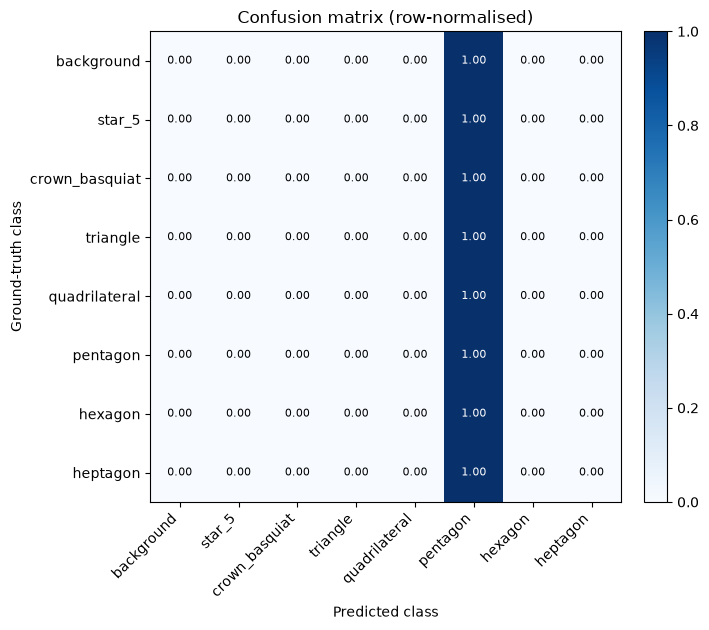

In [7]:
fig_cm = plot_confusion_matrix(val_results["confusion_matrix"], class_names=class_names, normalize=True, show=False)

## 5. Visualize Predictions

Visualization generated successfully.


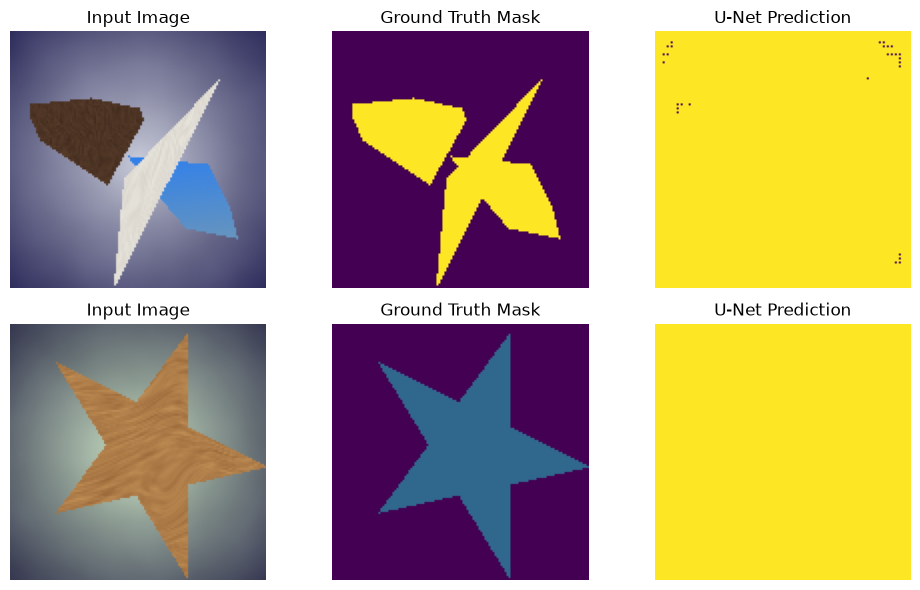

In [8]:
fig = visualize_predictions(model, val_loader, num_images=2, device=device, show=False)
print("Visualization generated successfully.")